In [1]:
# Environment setup: install only missing libraries in this notebook's Python environment.
# This does not change any data processing, model training, or evaluation logic.
import sys
import subprocess
import importlib.util

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "requests": "requests",
    "IPython": "ipython",
}
missing = [pkg for module, pkg in required_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All training dependencies are already installed.")


All training dependencies are already installed.


In [2]:
import sys, json, warnings, inspect, platform
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix)

try:
    import xgboost as xgb
except ImportError as err:
    raise ImportError("xgboost is missing -> run:  pip install xgboost") from err

try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# ---- Project root: Google Colab (Drive is mounted here) or local VS Code / Jupyter ----
IN_COLAB = False
try:
    from google.colab import drive          # only exists inside Google Colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/heatwave-delhi")      # folder must sit directly in My Drive
    ROOT.mkdir(parents=True, exist_ok=True)
else:
    _cwd = Path.cwd().resolve()
    if _cwd.name == "heatwave-delhi":
        ROOT = _cwd
    elif (_cwd / "heatwave-delhi").is_dir():
        ROOT = _cwd / "heatwave-delhi"
    elif _cwd.name == "notebooks":
        ROOT = _cwd.parent
    else:
        ROOT = _cwd
print("Project root:", ROOT)

DIRS = {
    "processed": ROOT / "data" / "processed",
    "config":    ROOT / "config",
    "models":    ROOT / "models",
    "model_rep": ROOT / "reports" / "model",
    "reports":   ROOT / "reports",
    "src":       ROOT / "src",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# the notebook-02 utilities (features / evaluation / heatwave rule) are reused, not rewritten
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
try:
    from src.features import (make_calendar, add_historical_features, add_seasonal_features,
                              add_trend_features, FEATURE_COLUMNS as ALL_FEATURES, META_COLS, HORIZONS, VARS)
    from src.evaluation import regression_metrics, regression_by_horizon, classification_metrics, to_heatwave_codes
    from src.heatwave_rules import classify_heatwave, CATEGORY_NAMES, HEATWAVE_C, SEVERE_C
except ImportError as err:
    raise ImportError("src/ modules not found - run 02_model_training.ipynb first (it creates them).") from err

print("Project root:", ROOT)
print("xgboost", xgb.__version__, "| python", platform.python_version())

Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi
Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi
xgboost 3.4.1 | python 3.14.6


In [3]:
# ----------------------- ALL project settings live here -----------------------
SEED = 42
TARGET = "target_tmax"
TRAIN_CSV = DIRS["processed"] / "train.csv"
VAL_CSV   = DIRS["processed"] / "validation.csv"
TEST_CSV  = DIRS["processed"] / "test.csv"          # opened ONLY in the final-evaluation step
CLEAN_CSV = DIRS["processed"] / "delhi_daily_clean.csv"

# Initial (untuned) model
INITIAL_PARAMS = dict(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                      min_child_weight=3, reg_lambda=1.0)
EARLY_STOPPING = 50                                  # stop when validation MAE has not improved for 50 rounds

# Hyper-parameter search (random search, judged on the VALIDATION split only)
N_TRIALS = 40
SEARCH_SPACE = {
    "max_depth":        [3, 4, 5, 6, 7, 8],
    "learning_rate":    [0.02, 0.03, 0.05, 0.08, 0.1],
    "min_child_weight": [1, 3, 5, 10],
    "subsample":        [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.8, 0.9, 1.0],
    "reg_lambda":       [0.5, 1, 2, 5, 10],
    "reg_alpha":        [0, 0.1, 0.5, 1],
    "gamma":            [0, 0.1, 0.5],
}

# Feature selection: prefer a smaller set if its validation MAE is within this tolerance of the best
SELECTION_TOLERANCE = 0.01          # °C
MUST_KEEP = ["forecast_horizon"]    # the model needs this to know which day it is predicting
TOP_K = 12

# Exploratory hot-day thresholds for extra classification metrics (the 45/47 °C rule is too rare in 2025)
HOT_CUTS = [40, 42]

TEST_EVAL_COUNT = 0                 # guard: the test split must be evaluated exactly once
print("Trials:", N_TRIALS, "| candidate features:", len(ALL_FEATURES))

Trials: 40 | candidate features: 21


LOAD MODEL-READY DATA

In [4]:
feature_cfg = json.loads((DIRS["config"] / "feature_config.json").read_text())
split_cfg = json.loads((DIRS["config"] / "split_config.json").read_text())
assert feature_cfg["feature_columns_in_order"] == ALL_FEATURES, "feature order differs from notebook 02"

train_df = pd.read_csv(TRAIN_CSV, parse_dates=META_COLS)
val_df   = pd.read_csv(VAL_CSV, parse_dates=META_COLS)
X_train, y_train = train_df[ALL_FEATURES], train_df[TARGET]
X_val,   y_val   = val_df[ALL_FEATURES],   val_df[TARGET]

checks = {
    "21 input features in the saved order": list(X_train.columns) == ALL_FEATURES == list(X_val.columns),
    "row counts match split_config.json": [len(train_df), len(val_df)] == [split_cfg["row_counts"]["train"], split_cfg["row_counts"]["validation"]],
    "train targets within 2015-2022": train_df["target_date"].between("2015-01-01", "2022-12-31").all(),
    "validation targets within 2023-2024": val_df["target_date"].between("2023-01-01", "2024-12-31").all(),
    "no missing values": not (X_train.isna().any().any() or X_val.isna().any().any() or y_train.isna().any() or y_val.isna().any()),
    "horizons are 1, 2, 3": sorted(train_df["forecast_horizon"].unique()) == HORIZONS,
}
result = pd.Series(checks, name="passed").to_frame()
display(result)
assert result["passed"].all()
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| target:", TARGET, "(°C)")
print("The TEST split is not opened until the final evaluation.")

,passed
21 input features in the saved order,True
row counts match split_config.json,True
train targets within 2015-2022,True
validation targets within 2023-2024,True
no missing values,True
"horizons are 1, 2, 3",True


Train: (8754, 21) | Validation: (2193, 21) | target: target_tmax (°C)
The TEST split is not opened until the final evaluation.


NO-TRAINING BASELINES (THE SCORE TO BEAT)

In [5]:
# Persistence = "tomorrow's Tmax equals today's Tmax" (needs no training)
base_val = regression_by_horizon(y_val, X_val["tmax_d0"], X_val["forecast_horizon"])
print("Persistence baseline on VALIDATION"); display(base_val.round(3))

Persistence baseline on VALIDATION


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,731.0,1.198,2.739,1.655,0.944,0.9,7.4,0.007
h=2,731.0,1.728,5.212,2.283,0.894,1.3,7.9,0.015
h=3,731.0,2.079,7.310,2.704,0.851,1.7,9.6,0.023
all,2193.0,1.669,5.087,2.255,0.896,1.3,9.6,0.015


INITIAL XGBOOST REGRESSOR

Best iteration (early stopping on validation MAE): 108


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,731.0,1.380,3.215,1.793,0.934,1.090,7.149,0.028
h=2,731.0,1.597,4.306,2.075,0.912,1.286,7.335,0.046
h=3,731.0,1.764,5.319,2.306,0.892,1.356,8.471,0.044
all,2193.0,1.580,4.280,2.069,0.913,1.239,8.471,0.039


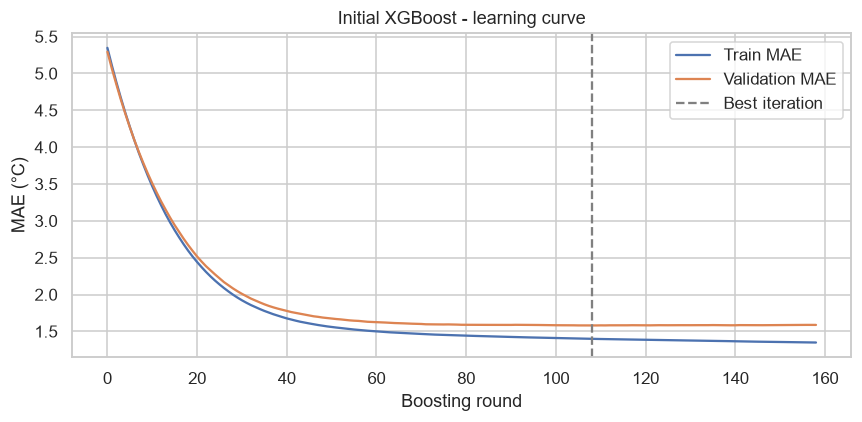

In [6]:
def make_model(params, n_estimators=None, early_stopping=EARLY_STOPPING):
    p = dict(INITIAL_PARAMS); p.update(params)
    if n_estimators is not None:
        p["n_estimators"] = n_estimators
    return xgb.XGBRegressor(objective="reg:squarederror", eval_metric="mae", tree_method="hist",
                            random_state=SEED, n_jobs=-1, early_stopping_rounds=early_stopping, **p)

init_model = make_model({})
init_model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print("Best iteration (early stopping on validation MAE):", init_model.best_iteration)

init_val = regression_by_horizon(y_val, init_model.predict(X_val), X_val["forecast_horizon"])
display(init_val.round(3))

# learning curve
hist = init_model.evals_result()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["validation_0"]["mae"], label="Train MAE"); ax.plot(hist["validation_1"]["mae"], label="Validation MAE")
ax.axvline(init_model.best_iteration, color="grey", ls="--", label="Best iteration")
ax.set_title("Initial XGBoost - learning curve"); ax.set_xlabel("Boosting round"); ax.set_ylabel("MAE (°C)"); ax.legend()
plt.tight_layout(); plt.savefig(DIRS["model_rep"] / "initial_learning_curve.png"); plt.show()

HYPER-PARAMETER TUNING (VALIDATION ONLY)

40 configurations tried | initial model validation MAE = 1.580 °C


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,best_iteration,val_MAE,val_RMSE
0,3,0.08,5,0.7,0.5,10.0,0.1,0.5,79,1.555,2.044
1,3,0.08,5,0.8,0.8,10.0,0.0,0.5,82,1.571,2.062
2,4,0.08,5,0.6,1.0,0.5,1.0,0.0,61,1.572,2.065
3,4,0.02,5,1.0,0.9,5.0,0.5,0.5,250,1.572,2.066
4,3,0.05,10,0.6,1.0,10.0,0.1,0.1,165,1.574,2.071
5,3,0.08,3,0.9,0.9,2.0,0.1,0.1,72,1.577,2.073
6,4,0.05,5,0.8,0.8,10.0,0.0,0.1,119,1.579,2.071
7,3,0.02,3,1.0,0.5,2.0,0.5,0.0,371,1.579,2.077



Best parameters: {'max_depth': 3, 'learning_rate': 0.08, 'min_child_weight': 5, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 10.0, 'reg_alpha': 0.1, 'gamma': 0.5}
Best validation MAE = 1.555 °C (vs initial 1.580)


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,731.0,1.350,3.102,1.761,0.937,1.031,7.241,0.043
h=2,731.0,1.574,4.198,2.049,0.914,1.215,8.136,0.041
h=3,731.0,1.742,5.230,2.287,0.893,1.323,8.502,0.039
all,2193.0,1.555,4.177,2.044,0.915,1.193,8.502,0.041


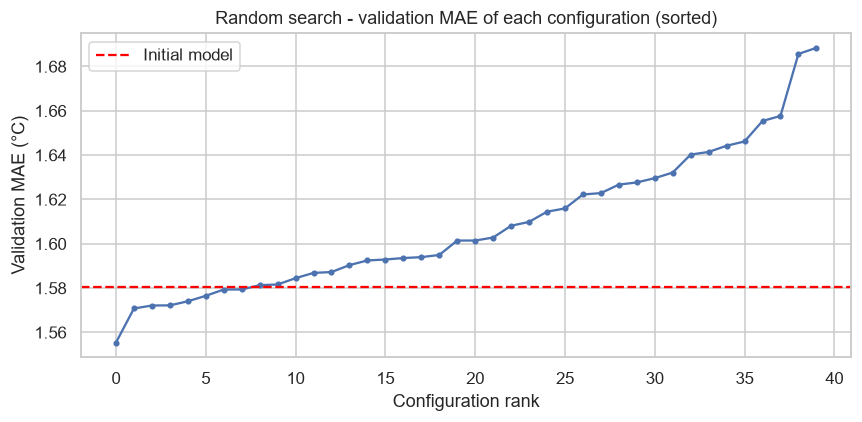

In [7]:
rng = np.random.default_rng(SEED)
trials = []
for i in range(N_TRIALS):
    params = {k: v[int(rng.integers(len(v)))] for k, v in SEARCH_SPACE.items()}
    m = make_model(params)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    pred = m.predict(X_val)
    trials.append({**params, "best_iteration": int(m.best_iteration) + 1,
                   "val_MAE": float(np.mean(np.abs(pred - y_val))),
                   "val_RMSE": float(np.sqrt(np.mean((pred - y_val) ** 2)))})

trials_df = pd.DataFrame(trials).sort_values(["val_MAE", "val_RMSE"]).reset_index(drop=True)
init_mae = float(init_val.loc["all", "MAE (°C)"])
print(f"{N_TRIALS} configurations tried | initial model validation MAE = {init_mae:.3f} °C")
display(trials_df.head(8).round(3))

best_params = {k: trials_df.loc[0, k] for k in SEARCH_SPACE}
best_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.items()}
best_row = trials_df.loc[0]
print("\nBest parameters:", best_params)
print(f"Best validation MAE = {best_row['val_MAE']:.3f} °C (vs initial {init_mae:.3f})")

# keep the initial parameters if tuning did not actually help
if best_row["val_MAE"] >= init_mae:
    print("Tuning did not beat the initial model -> keeping the initial parameters.")
    best_params = {k: INITIAL_PARAMS[k] for k in SEARCH_SPACE if k in INITIAL_PARAMS}

tuned_model = make_model(best_params)
tuned_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
tuned_val = regression_by_horizon(y_val, tuned_model.predict(X_val), X_val["forecast_horizon"])
display(tuned_val.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trials_df["val_MAE"].values, marker="o", ms=3)
ax.axhline(init_mae, color="red", ls="--", label="Initial model")
ax.set_title("Random search - validation MAE of each configuration (sorted)")
ax.set_xlabel("Configuration rank"); ax.set_ylabel("Validation MAE (°C)"); ax.legend()
plt.tight_layout(); plt.savefig(DIRS["model_rep"] / "tuning_results.png"); plt.show()

FEATURE IMPORTANCE AND FEATURE SELECTION (TRAIN + VALIDATION ONLY)

,gain_share,perm_MAE_increase,perm_std
tmax_d0,0.3176,1.8832,0.0478
tmax_mean_3d,0.3526,0.7513,0.0210
day_cos,0.0890,0.6984,0.0197
solar_d0,0.0377,0.1850,0.0106
solar_sum_3d,0.0828,0.0957,0.0074
month_cos,0.0552,0.0838,0.0068
humidity_d0,0.0136,0.0505,0.0042
day_sin,0.0121,0.0424,0.0034
humidity_mean_3d,0.0052,0.0213,0.0025
tmax_d1,0.0053,0.0092,0.0017


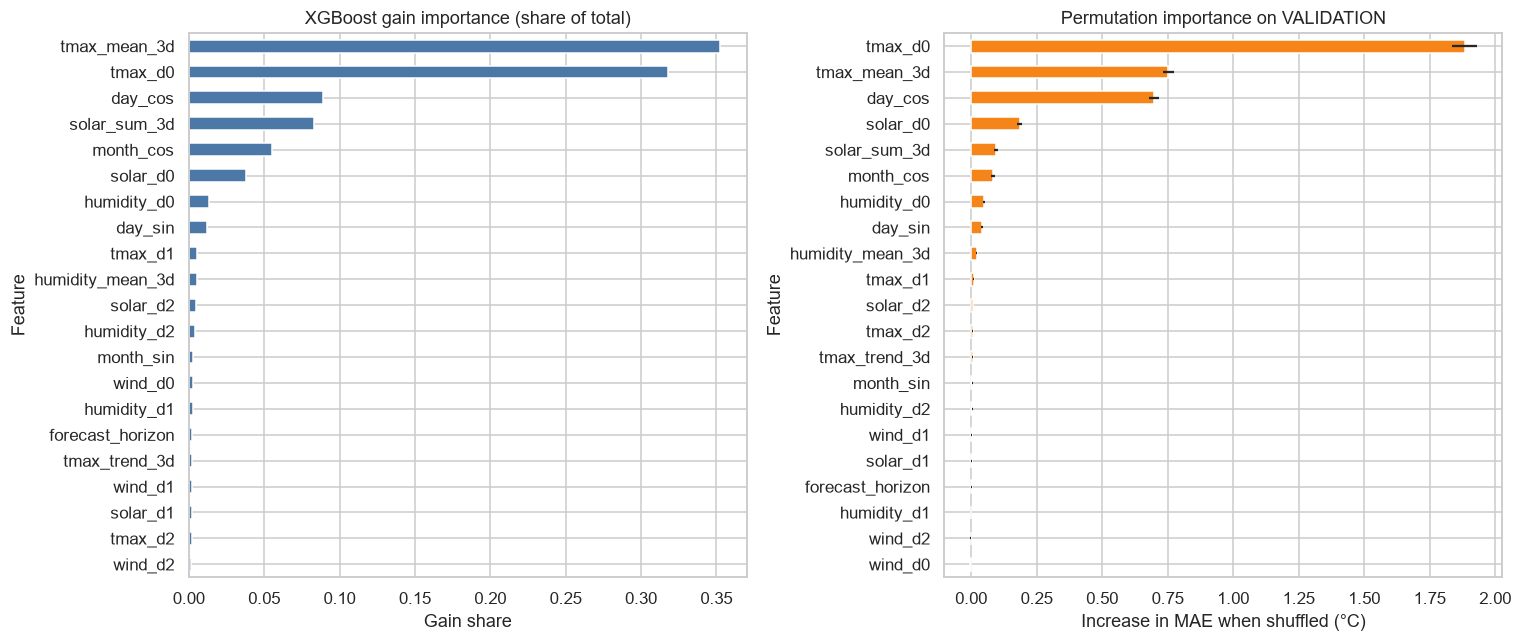

In [8]:
gain = pd.Series(tuned_model.get_booster().get_score(importance_type="gain")).reindex(ALL_FEATURES).fillna(0)
gain = gain / gain.sum()

perm = permutation_importance(tuned_model, X_val, y_val, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({"gain_share": gain, "perm_MAE_increase": perm.importances_mean,
                           "perm_std": perm.importances_std}).sort_values("perm_MAE_increase", ascending=False)
display(importance.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
importance["gain_share"].sort_values().plot(kind="barh", ax=ax[0], color="#4c78a8")
ax[0].set_title("XGBoost gain importance (share of total)"); ax[0].set_xlabel("Gain share"); ax[0].set_ylabel("Feature")
importance["perm_MAE_increase"].sort_values().plot(kind="barh", ax=ax[1], xerr=importance["perm_std"].reindex(importance["perm_MAE_increase"].sort_values().index), color="#f58518")
ax[1].set_title("Permutation importance on VALIDATION"); ax[1].set_xlabel("Increase in MAE when shuffled (°C)"); ax[1].set_ylabel("Feature")
plt.tight_layout(); plt.savefig(DIRS["model_rep"] / "feature_importance.png"); plt.show()

In [9]:
# Candidate feature sets (decided from train/validation results only - the test split is untouched)
by_perm = importance["perm_MAE_increase"].sort_values(ascending=False).index.tolist()
positive = [f for f in ALL_FEATURES if importance.loc[f, "perm_MAE_increase"] > 0 or f in MUST_KEEP]
topk = list(dict.fromkeys(by_perm[:TOP_K] + MUST_KEEP))
candidates = {
    f"all {len(ALL_FEATURES)} features": ALL_FEATURES,
    f"positive permutation importance ({len(positive)})": [f for f in ALL_FEATURES if f in positive],
    f"top {TOP_K} by permutation importance (+horizon)": [f for f in ALL_FEATURES if f in topk],
}

rows = []
for name, feats in candidates.items():
    m = make_model(best_params)
    m.fit(X_train[feats], y_train, eval_set=[(X_val[feats], y_val)], verbose=False)
    pred = m.predict(X_val[feats])
    rows.append({"feature set": name, "n_features": len(feats), "best_iteration": int(m.best_iteration) + 1,
                 "val_MAE": float(np.mean(np.abs(pred - y_val))), "val_RMSE": float(np.sqrt(np.mean((pred - y_val) ** 2)))})
selection = pd.DataFrame(rows)
display(selection.round(4))

# Rule: smallest set whose validation MAE is within SELECTION_TOLERANCE of the best
best_mae = selection["val_MAE"].min()
ok = selection[selection["val_MAE"] <= best_mae + SELECTION_TOLERANCE].sort_values(["n_features", "val_MAE"])
chosen_name = ok.iloc[0]["feature set"]
SELECTED = candidates[chosen_name]
assert all(f in SELECTED for f in MUST_KEEP)
print(f"Chosen set: {chosen_name} -> {len(SELECTED)} features")
print("Dropped:", [f for f in ALL_FEATURES if f not in SELECTED] or "none")

,feature set,n_features,best_iteration,val_MAE,val_RMSE
0,all 21 features,21,79,1.5554,2.0437
1,positive permutation importance (19),19,83,1.5647,2.0546
2,top 12 by permutation importance (+horizon),13,82,1.5578,2.0508


Chosen set: top 12 by permutation importance (+horizon) -> 13 features
Dropped: ['humidity_d1', 'humidity_d2', 'wind_d0', 'wind_d1', 'wind_d2', 'solar_d1', 'month_sin', 'tmax_trend_3d']


FINAL MODEL (TRAIN + VALIDATION)

In [10]:
# 1) Train-only model with the chosen features -> honest validation numbers + the best number of trees
sel_model = make_model(best_params)
sel_model.fit(X_train[SELECTED], y_train, eval_set=[(X_val[SELECTED], y_val)], verbose=False)
n_trees = int(sel_model.best_iteration) + 1
val_pred = sel_model.predict(X_val[SELECTED])
val_table = regression_by_horizon(y_val, val_pred, X_val["forecast_horizon"])
print(f"Train-only model, {n_trees} trees - VALIDATION metrics:"); display(val_table.round(3))

# 2) Final model: same parameters, retrained on train + validation (the 2023-24 weather is real history we
#    may use), number of trees scaled by the larger training size. No early stopping (no hold-out left to watch).
X_full = pd.concat([X_train, X_val])[SELECTED]
y_full = pd.concat([y_train, y_val])
n_final = int(round(n_trees * len(X_full) / len(X_train)))
final_model = make_model(best_params, n_estimators=n_final, early_stopping=None)
final_model.fit(X_full, y_full, verbose=False)
print(f"Final model: {n_final} trees, trained on {len(X_full)} rows (train + validation), {len(SELECTED)} features")

Train-only model, 82 trees - VALIDATION metrics:


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,731.0,1.357,3.168,1.780,0.935,1.059,7.802,0.078
h=2,731.0,1.575,4.202,2.050,0.914,1.237,7.579,0.076
h=3,731.0,1.742,5.247,2.291,0.893,1.334,8.150,0.074
all,2193.0,1.558,4.206,2.051,0.914,1.202,8.150,0.076


Final model: 103 trees, trained on 10947 rows (train + validation), 13 features


FINAL EVALUATION ON THE TEST SET (ONCE)

In [11]:
# The test split is opened here for the first and only time. Nothing above used it.
test_df = pd.read_csv(TEST_CSV, parse_dates=META_COLS)
assert test_df["target_date"].between("2025-01-01", "2025-12-31").all()
X_test, y_test = test_df[ALL_FEATURES], test_df[TARGET]
TEST_EVAL_COUNT += 1

test_pred = final_model.predict(X_test[SELECTED])
test_table = regression_by_horizon(y_test, test_pred, X_test["forecast_horizon"])
base_test = regression_by_horizon(y_test, X_test["tmax_d0"], X_test["forecast_horizon"])

print("XGBoost - TEST metrics per horizon"); display(test_table.round(3))
print("Persistence baseline - TEST"); display(base_test.round(3))

cmp = pd.DataFrame({
    "XGBoost MAE": test_table["MAE (°C)"], "Persistence MAE": base_test["MAE (°C)"],
    "XGBoost RMSE": test_table["RMSE (°C)"], "Persistence RMSE": base_test["RMSE (°C)"],
    "XGBoost R²": test_table["R²"], "Persistence R²": base_test["R²"]})
cmp["MAE improvement %"] = (1 - cmp["XGBoost MAE"] / cmp["Persistence MAE"]) * 100
display(cmp.round(3))

XGBoost - TEST metrics per horizon


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,365.0,1.272,3.059,1.749,0.923,0.915,6.715,0.087
h=2,365.0,1.566,4.269,2.066,0.892,1.227,7.121,0.072
h=3,365.0,1.733,5.113,2.261,0.871,1.366,7.200,0.057
all,1095.0,1.524,4.147,2.036,0.895,1.143,7.200,0.072


Persistence baseline - TEST


,n,MAE (°C),MSE (°C²),RMSE (°C),R²,MedAE (°C),Max error (°C),Bias (°C)
h=1,365.0,1.330,3.479,1.865,0.912,1.0,7.4,-0.012
h=2,365.0,1.843,5.852,2.419,0.852,1.5,8.1,-0.021
h=3,365.0,2.158,7.484,2.736,0.811,1.8,8.9,-0.027
all,1095.0,1.777,5.605,2.368,0.859,1.4,8.9,-0.020


,XGBoost MAE,Persistence MAE,XGBoost RMSE,Persistence RMSE,XGBoost R²,Persistence R²,MAE improvement %
h=1,1.272,1.330,1.749,1.865,0.923,0.912,4.361
h=2,1.566,1.843,2.066,2.419,0.892,0.852,15.016
h=3,1.733,2.158,2.261,2.736,0.871,0.811,19.671
all,1.524,1.777,2.036,2.368,0.895,0.859,14.242


In [12]:
# ---- Classification-style metrics (heatwave rule + exploratory hot-day cut-offs) ----
def hot_day_metrics(y_true, y_pred, cut):
    # Binary "Tmax >= cut" classification: accuracy, precision, recall, F1, support (actual hot days).
    t, p = np.asarray(y_true) >= cut, np.asarray(y_pred) >= cut
    prec, rec, f1, _ = precision_recall_fscore_support(t, p, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[False, True]).ravel()
    return {"cut (°C)": cut, "accuracy": accuracy_score(t, p), "precision": prec, "recall": rec, "f1": f1,
            "support (actual hot days)": int(t.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

# the validation numbers come from the train-only model; the test numbers from the final model
sets = {"validation": (y_val, val_pred, X_val["forecast_horizon"]), "test": (y_test, test_pred, X_test["forecast_horizon"])}
clf_rows, hot_rows = [], []
for name, (yt, yp, hz) in sets.items():
    summ, per_class, cm = classification_metrics(yt, yp)
    print("=" * 78); print(f"{name.upper()} | heatwave rule (0 / 1 / 2) | accuracy = {summ['accuracy']:.4f} | support = {summ['total support']}")
    display(per_class.round(3)); display(cm)
    clf_rows.append({"split": name, **summ})
    for cut in HOT_CUTS:
        hot_rows.append({"split": name, **hot_day_metrics(yt, yp, cut)})
clf_summary = pd.DataFrame(clf_rows)
hot_summary = pd.DataFrame(hot_rows)
print("=" * 78); print("Exploratory hot-day classification (Tmax >= cut-off):"); display(hot_summary.round(3))
print("NOTE: classes 1/2 (>= 45 °C) have no test examples, so the rule-based accuracy there is trivial.")
print("      The 40 / 42 °C cut-offs give a more meaningful recall + support check on hot days.")

VALIDATION | heatwave rule (0 / 1 / 2) | accuracy = 0.9863 | support = 2193


,precision,recall,f1,support
0 - No Heatwave,0.986,1.0,0.993,2163
1 - Heatwave,0.000,0.0,0.000,30
2 - Severe Heatwave,0.000,0.0,0.000,0


,pred 0,pred 1,pred 2
actual 0,2163,0,0
actual 1,30,0,0
actual 2,0,0,0


TEST | heatwave rule (0 / 1 / 2) | accuracy = 1.0000 | support = 1095


,precision,recall,f1,support
0 - No Heatwave,1.0,1.0,1.0,1095
1 - Heatwave,0.0,0.0,0.0,0
2 - Severe Heatwave,0.0,0.0,0.0,0


,pred 0,pred 1,pred 2
actual 0,1095,0,0
actual 1,0,0,0
actual 2,0,0,0


Exploratory hot-day classification (Tmax >= cut-off):


,split,cut (°C),accuracy,precision,recall,f1,support (actual hot days),TP,FP,FN,TN
0,validation,40,0.961,0.820,0.714,0.763,192,137,30,55,1971
1,validation,42,0.967,0.968,0.294,0.451,102,30,1,72,2090
2,test,40,0.952,0.738,0.571,0.644,84,48,17,36,994
3,test,42,0.970,0.714,0.139,0.233,36,5,2,31,1057


NOTE: classes 1/2 (>= 45 °C) have no test examples, so the rule-based accuracy there is trivial.
      The 40 / 42 °C cut-offs give a more meaningful recall + support check on hot days.


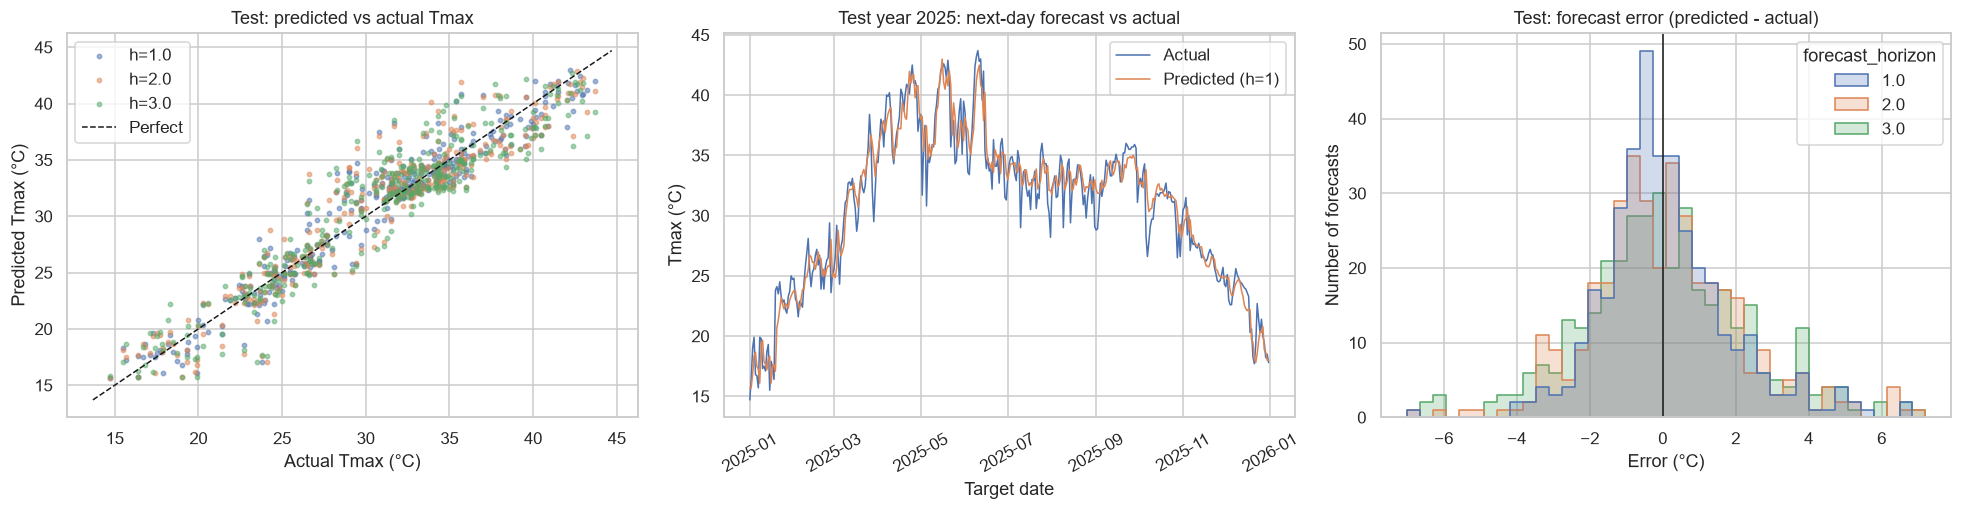

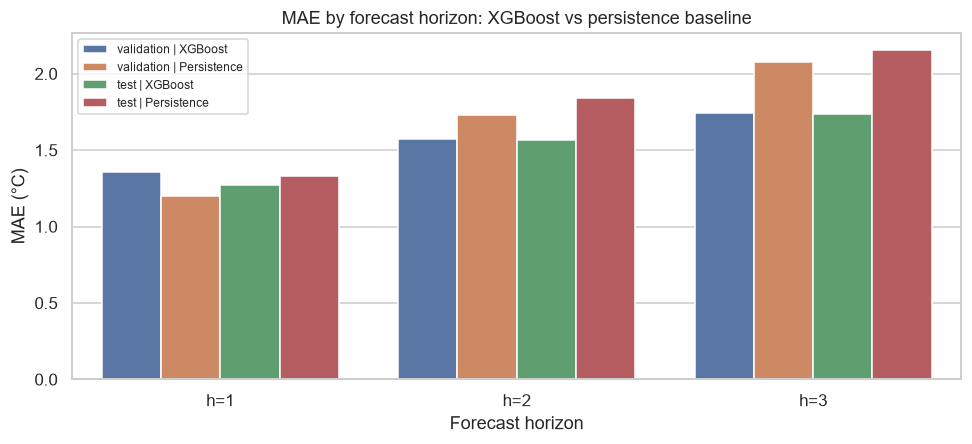

Test days with actual Tmax >= 40 °C: 84 forecasts | mean error -1.56 °C | MAE 1.75 °C


C:\Users\Shreya Mehrotra\AppData\Local\Temp\ipykernel_25964\2581162353.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(hot.head(8).round(2))


,forecast_origin,target_date,forecast_horizon,actual,predicted,error
481,2025-06-08,2025-06-10,2.0,43.7,41.130001,-2.57
482,2025-06-07,2025-06-10,3.0,43.7,39.230000,-4.47
480,2025-06-09,2025-06-10,1.0,43.7,41.980000,-1.72
477,2025-06-08,2025-06-09,1.0,43.2,41.240002,-1.96
479,2025-06-06,2025-06-09,3.0,43.2,37.080002,-6.12
478,2025-06-07,2025-06-09,2.0,43.2,39.230000,-3.97
487,2025-06-10,2025-06-12,2.0,43.0,42.240002,-0.76
486,2025-06-11,2025-06-12,1.0,43.0,40.849998,-2.15


In [13]:
# ---- Plots ----
res = test_df[META_COLS + ["forecast_horizon"]].copy()
res["actual"], res["predicted"] = y_test.values, test_pred
res["error"] = res["predicted"] - res["actual"]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for h, g in res.groupby("forecast_horizon"):
    ax[0].scatter(g["actual"], g["predicted"], s=8, alpha=0.5, label=f"h={h}")
lims = [res[["actual", "predicted"]].min().min() - 1, res[["actual", "predicted"]].max().max() + 1]
ax[0].plot(lims, lims, "k--", lw=1, label="Perfect")
ax[0].set_title("Test: predicted vs actual Tmax"); ax[0].set_xlabel("Actual Tmax (°C)"); ax[0].set_ylabel("Predicted Tmax (°C)"); ax[0].legend()

g1 = res[res["forecast_horizon"] == 1].sort_values("target_date")
ax[1].plot(g1["target_date"], g1["actual"], lw=1, label="Actual")
ax[1].plot(g1["target_date"], g1["predicted"], lw=1, label="Predicted (h=1)")
ax[1].set_title("Test year 2025: next-day forecast vs actual"); ax[1].set_xlabel("Target date"); ax[1].set_ylabel("Tmax (°C)"); ax[1].legend()
ax[1].tick_params(axis="x", rotation=30)

sns.histplot(data=res, x="error", hue="forecast_horizon", bins=40, element="step", palette="deep", ax=ax[2])
ax[2].axvline(0, color="k", lw=1)
ax[2].set_title("Test: forecast error (predicted - actual)"); ax[2].set_xlabel("Error (°C)"); ax[2].set_ylabel("Number of forecasts")
plt.tight_layout(); plt.savefig(DIRS["model_rep"] / "test_predictions.png"); plt.show()

# MAE by horizon: XGBoost vs baseline, validation and test
rows = []
for split, tbl, base in [("validation", val_table, base_val), ("test", test_table, base_test)]:
    for h in ("h=1", "h=2", "h=3"):
        rows += [{"split": split, "horizon": h, "model": "XGBoost", "MAE (°C)": tbl.loc[h, "MAE (°C)"]},
                 {"split": split, "horizon": h, "model": "Persistence", "MAE (°C)": base.loc[h, "MAE (°C)"]}]
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=pd.DataFrame(rows), x="horizon", y="MAE (°C)", hue=pd.DataFrame(rows)["split"] + " | " + pd.DataFrame(rows)["model"], ax=ax)
ax.set_title("MAE by forecast horizon: XGBoost vs persistence baseline"); ax.set_xlabel("Forecast horizon"); ax.set_ylabel("MAE (°C)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(DIRS["model_rep"] / "mae_by_horizon.png"); plt.show()

# the hottest days: how well were they predicted?
hot = res[res["actual"] >= 40].sort_values("actual", ascending=False)
print(f"Test days with actual Tmax >= 40 °C: {len(hot)} forecasts | mean error {hot['error'].mean():.2f} °C | MAE {hot['error'].abs().mean():.2f} °C")
display(hot.head(8).round(2))

SAVE THE MODEL, METADATA AND PREDICTIONS

In [14]:
MODEL_PATH = DIRS["models"] / "xgb_tmax_regressor.json"
final_model.save_model(MODEL_PATH)

# predictions + heatwave category (rule applied AFTER regression)
res["pred_category"] = [classify_heatwave(float(t))[1] for t in res["predicted"]]
res["actual_category"] = [classify_heatwave(float(t))[1] for t in res["actual"]]
res.round(3).to_csv(DIRS["model_rep"] / "test_predictions.csv", index=False)

vres = val_df[META_COLS + ["forecast_horizon"]].copy()
vres["actual"], vres["predicted"] = y_val.values, val_pred
vres.round(3).to_csv(DIRS["model_rep"] / "validation_predictions.csv", index=False)

val_table.round(4).to_csv(DIRS["model_rep"] / "metrics_validation.csv")
test_table.round(4).to_csv(DIRS["model_rep"] / "metrics_test.csv")
clf_summary.round(4).to_csv(DIRS["model_rep"] / "metrics_heatwave_rule.csv", index=False)
hot_summary.round(4).to_csv(DIRS["model_rep"] / "metrics_hot_days.csv", index=False)
trials_df.round(4).to_csv(DIRS["model_rep"] / "tuning_trials.csv", index=False)
importance.round(5).to_csv(DIRS["model_rep"] / "feature_importance.csv")

model_metadata = {
    "model": "XGBRegressor (single pooled direct multi-horizon model)",
    "target": {"name": TARGET, "unit": "°C"}, "horizons": HORIZONS,
    "selected_features_in_order": SELECTED, "all_candidate_features": ALL_FEATURES,
    "dropped_features": [f for f in ALL_FEATURES if f not in SELECTED],
    "feature_selection": {"chosen_set": chosen_name, "rule": f"smallest set within {SELECTION_TOLERANCE} °C validation MAE of the best",
                          "decided_on": "train + validation only"},
    "hyper_parameters": best_params, "n_estimators": n_final, "seed": SEED,
    "trained_on": {"split": "train + validation", "rows": int(len(X_full)), "target_dates": "2015-01-04 to 2024-12-31"},
    "metrics": {"validation_all_horizons": {k: float(v) for k, v in val_table.loc["all"].items()},
                "test_all_horizons": {k: float(v) for k, v in test_table.loc["all"].items()},
                "test_by_horizon": {h: {k: float(v) for k, v in test_table.loc[h].items()} for h in ("h=1", "h=2", "h=3")}},
    "heatwave_rule": {"type": "simplified absolute temperature (not the full IMD definition)",
                      "heatwave_c": HEATWAVE_C, "severe_c": SEVERE_C},
    "versions": {"xgboost": xgb.__version__, "python": platform.python_version()},
    "trained_at": f"{datetime.now():%Y-%m-%d %H:%M}",
    "caveat": "Trained on Open-Meteo Archive (ERA5) data; live inputs come from the operational Forecast API, a possibly "
              "different model product - check live-input compatibility before trusting live forecasts."}
(DIRS["models"] / "model_metadata.json").write_text(json.dumps(model_metadata, indent=2, ensure_ascii=False))

# reload test: the saved file must give identical predictions
reloaded = xgb.XGBRegressor(); reloaded.load_model(MODEL_PATH)
assert np.allclose(reloaded.predict(X_test[SELECTED]), test_pred), "reloaded model differs!"
print("Saved:", MODEL_PATH.relative_to(ROOT), "+ model_metadata.json | reload check passed")

Saved: models\xgb_tmax_regressor.json + model_metadata.json | reload check passed


C:\Users\Shreya Mehrotra\AppData\Local\Temp\ipykernel_25964\673198884.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  res.round(3).to_csv(DIRS["model_rep"] / "test_predictions.csv", index=False)
C:\Users\Shreya Mehrotra\AppData\Local\Temp\ipykernel_25964\673198884.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  vres.round(3).to_csv(DIRS["model_rep"] / "validation_predictions.csv", index=False)


LIVE PREDICTION PIPELINE (OPEN-METEO FORECAST API)

In [15]:
# Live code: 3 COMPLETED days -> the same 21 features -> one row per horizon -> same model -> heatwave rule.
import requests

FORECAST_API_URL = "https://api.open-meteo.com/v1/forecast"
LAT, LON, TZ = 28.61, 77.21, "Asia/Kolkata"
API_VARS = {"temperature_2m_max": "tmax", "relative_humidity_2m_mean": "humidity",
            "wind_speed_10m_max": "wind", "shortwave_radiation_sum": "solar"}


def fetch_recent_daily(latitude=LAT, longitude=LON, past_days=7, timeout=30):
    # Recent daily weather from the operational Forecast API (same units as training). Fails loudly.
    params = {"latitude": latitude, "longitude": longitude, "daily": ",".join(API_VARS), "timezone": TZ,
              "temperature_unit": "celsius", "wind_speed_unit": "kmh", "past_days": past_days, "forecast_days": 1}
    try:
        resp = requests.get(FORECAST_API_URL, params=params, timeout=timeout)
    except requests.RequestException as err:
        raise RuntimeError(f"Network/API request failed: {err}") from err
    if resp.status_code != 200:
        raise RuntimeError(f"Open-Meteo returned HTTP {resp.status_code}: {resp.text[:300]}")
    daily = resp.json().get("daily")
    if not daily or "time" not in daily:
        raise RuntimeError("API response has no 'daily' block")
    out = pd.DataFrame({"date": pd.to_datetime(daily["time"])})
    for api_name, name in API_VARS.items():
        if api_name not in daily:
            raise RuntimeError(f"API response is missing {api_name}")
        out[name] = pd.to_numeric(pd.Series(daily[api_name]), errors="coerce")
    return out


def last_three_completed_days(df, today=None):
    # Drop today (incomplete) and keep the 3 latest COMPLETE consecutive days with no missing values.
    if today is None:
        today = pd.Timestamp.now(tz=TZ).tz_localize(None).normalize()
    done = df[df["date"] < today].sort_values("date").tail(3).reset_index(drop=True)
    if len(done) < 3 or done[VARS].isna().any().any():
        raise ValueError("Need 3 completed days with all four variables present.")
    if (done["date"].diff().dropna() != pd.Timedelta(days=1)).any():
        raise ValueError("The 3 input days are not consecutive.")
    return done


def build_live_features(last_three):
    # Same code path as training: T = last completed day; one row per horizon; seasonal features of the TARGET date.
    cal = make_calendar(last_three)
    if len(cal) != 3 or cal.isna().any().any():
        raise ValueError("Need exactly 3 consecutive completed days with no missing values.")
    hist = add_trend_features(add_historical_features(cal)).iloc[[-1]]
    origin = hist.index[0]
    rows = []
    for h in HORIZONS:
        r = hist.copy().reset_index(drop=True)
        td = origin + pd.Timedelta(days=h)
        r["forecast_horizon"] = h
        r = pd.concat([r, add_seasonal_features([td])], axis=1)
        r.insert(0, "target_date", td)
        r.insert(0, "forecast_origin", origin)
        rows.append(r)
    return pd.concat(rows, ignore_index=True)[META_COLS + ALL_FEATURES]


def predict_next_three_days(model, last_three, feature_columns=None):
    # One feature row per horizon -> the SAME regressor -> the separate heatwave rule.
    rows = build_live_features(last_three)
    cols = feature_columns or ALL_FEATURES
    pred = model.predict(rows[cols])
    out = rows[META_COLS + ["forecast_horizon"]].copy()
    out["predicted_tmax"] = pred
    codes = [classify_heatwave(float(t)) for t in pred]
    out["category_code"] = [c for c, _ in codes]
    out["category"] = [n for _, n in codes]
    return out

In [16]:
# ---- Offline proof (no internet needed): the live pipeline reproduces the training rows exactly ----
clean = pd.read_csv(CLEAN_CSV, parse_dates=["date"])
origin = pd.Timestamp("2025-06-10")
last3 = clean[(clean["date"] >= origin - pd.Timedelta(days=2)) & (clean["date"] <= origin)]
live_out = predict_next_three_days(final_model, last3, SELECTED)

ref = test_df[test_df["forecast_origin"] == origin].sort_values("forecast_horizon")
assert np.allclose(build_live_features(last3)[ALL_FEATURES].to_numpy(float), ref[ALL_FEATURES].to_numpy(float))
assert np.allclose(live_out["predicted_tmax"], final_model.predict(ref[SELECTED]))
print("Live feature builder == training features for origin", origin.date(), "(3 rows x 21 features)")
actual = clean.set_index("date")["tmax"].reindex(live_out["target_date"]).values
live_out["actual_tmax"] = actual
display(live_out.round({"predicted_tmax": 2}))

# ---- Optional: real live call (needs internet; works on Colab) ----
try:
    recent = fetch_recent_daily()
    three = last_three_completed_days(recent)
    print("\nLive inputs (3 completed days):"); display(three)
    live_now = predict_next_three_days(final_model, three, SELECTED)
    display(live_now.round({"predicted_tmax": 2}))
except Exception as err:
    print("\nLive API call skipped here:", err)
    print("(This is only a connectivity matter - the pipeline itself was verified offline above.)")

Live feature builder == training features for origin 2025-06-10 (3 rows x 21 features)


,forecast_origin,target_date,forecast_horizon,predicted_tmax,category_code,category,actual_tmax
0,2025-06-10,2025-06-11,1,42.490002,0,No Heatwave,42.8
1,2025-06-10,2025-06-12,2,42.240002,0,No Heatwave,43.0
2,2025-06-10,2025-06-13,3,42.189999,0,No Heatwave,39.6



Live inputs (3 completed days):


,date,tmax,humidity,wind,solar
0,2026-11-19,24.5,64,4.5,13.74
1,2026-11-20,24.5,66,4.3,13.66
2,2026-11-21,24.7,70,5.8,13.11


,forecast_origin,target_date,forecast_horizon,predicted_tmax,category_code,category
0,2026-11-21,2026-11-22,1,25.08,0,No Heatwave
1,2026-11-21,2026-11-23,2,25.08,0,No Heatwave
2,2026-11-21,2026-11-24,3,25.08,0,No Heatwave


EXPORT LIVE MODULE, STREAMLIT APP AND REQUIREMENTS

In [17]:
live_header = ('"""Auto-generated from 03_xgboost_training.ipynb - live prediction for the Delhi 3-day Tmax model."""\n'
               "import numpy as np\nimport pandas as pd\nimport requests\n\n"
               "from src.features import (make_calendar, add_historical_features, add_seasonal_features, add_trend_features,\n"
               "                          FEATURE_COLUMNS as ALL_FEATURES, META_COLS, HORIZONS, VARS)\n"
               "from src.heatwave_rules import classify_heatwave\n\n"
               f"FORECAST_API_URL = {FORECAST_API_URL!r}\nLAT, LON, TZ = {LAT}, {LON}, {TZ!r}\nAPI_VARS = {API_VARS!r}\n")
funcs = [fetch_recent_daily, last_three_completed_days, build_live_features, predict_next_three_days]
try:
    (DIRS["src"] / "live.py").write_text(live_header + "\n\n" + "\n\n".join(inspect.getsource(f) for f in funcs) + "\n")
    print("src/live.py written")
except OSError as err:
    print("Could not export src/live.py:", err)

app_code = """\
import json, sys
from pathlib import Path

import pandas as pd
import streamlit as st
import xgboost as xgb

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT))
from src.live import fetch_recent_daily, last_three_completed_days, predict_next_three_days
from src.features import VARS

st.set_page_config(page_title="Delhi Heatwave Forecast", layout="wide")
st.title("Delhi 3-Day Maximum Temperature & Heatwave Forecast")
st.caption("One XGBoost regressor predicts Tmax for the next 3 days; a separate rule then labels each day.")


@st.cache_resource
def load_model():
    meta = json.loads((ROOT / "models" / "model_metadata.json").read_text())
    model = xgb.XGBRegressor()
    model.load_model(ROOT / "models" / "xgb_tmax_regressor.json")
    return model, meta


@st.cache_data(ttl=3600)
def live_inputs():
    return last_three_completed_days(fetch_recent_daily())


model, meta = load_model()
use_offline = st.sidebar.checkbox("Use offline sample (last 3 days of the dataset)", value=False)

try:
    if use_offline:
        clean = pd.read_csv(ROOT / "data" / "processed" / "delhi_daily_clean.csv", parse_dates=["date"])
        last3 = clean.tail(3).reset_index(drop=True)
        st.info("Offline sample mode - these are the last 3 days of the historical dataset, not live data.")
    else:
        last3 = live_inputs()
except Exception as err:
    st.error(f"Could not get live data: {err}")
    st.write("Tick the offline-sample box in the sidebar to try the app without internet.")
    st.stop()

st.subheader("Input: last 3 completed days")
st.dataframe(last3.assign(date=last3["date"].dt.date), hide_index=True)

pred = predict_next_three_days(model, last3, meta["selected_features_in_order"])

st.subheader("Forecast")
cols = st.columns(3)
for col, (_, r) in zip(cols, pred.iterrows()):
    col.metric(f"{r['target_date']:%a %d %b %Y} (day +{int(r['forecast_horizon'])})",
               f"{r['predicted_tmax']:.1f} °C", r["category"], delta_color="off")

show = pred[["target_date", "forecast_horizon", "predicted_tmax", "category"]].copy()
show["target_date"] = show["target_date"].dt.date
show["predicted_tmax"] = show["predicted_tmax"].round(1)
st.dataframe(show, hide_index=True)
st.bar_chart(pred.set_index(pred["target_date"].dt.strftime("%d %b"))["predicted_tmax"])

st.subheader("How to read this")
st.markdown(
    "- **Categories** use a *simplified absolute-temperature rule*: below 45 °C = No Heatwave, 45 to <47 °C = Heatwave, "
    "47 °C or more = Severe Heatwave. This is **not** the full IMD definition (departure from normal, spatial coverage, duration).\\n"
    "- The model was trained on ERA5 *archive* data; live inputs come from the operational *forecast* API, which may be a "
    "different model product, so live accuracy can differ from the test results.\\n"
    f"- Test MAE of the model over all 3 horizons: **{meta['metrics']['test_all_horizons']['MAE (°C)']:.2f} °C**."
)
"""
if not (ROOT / "app.py").exists():        # never overwrite the full dashboard
    (ROOT / "app.py").write_text(app_code)

requirements = "numpy\npandas\nmatplotlib\nseaborn\nscipy\nstatsmodels\nscikit-learn\nxgboost\njoblib\nrequests\nstreamlit\n"
if not (ROOT / "requirements.txt").exists():
    (ROOT / "requirements.txt").write_text(requirements)
print("Saved: app.py, requirements.txt")

src/live.py written
Saved: app.py, requirements.txt


MODEL TRAINING REPORT AND FINAL CHECKS

In [18]:
report = f"""# Model Training Summary - Delhi 3-day Tmax (XGBoost Regressor)
Generated: {datetime.now():%Y-%m-%d %H:%M}

## Setup
- One pooled XGBoost regressor, direct multi-horizon (horizon 1, 2, 3 via the forecast_horizon feature).
- Target: {TARGET} (°C). Train {len(train_df)} rows (2015-2022 targets), validation {len(val_df)} (2023-2024), test {len(test_df)} (2025).

## Tuning (validation only)
- Initial model validation MAE: {init_mae:.3f} °C | best of {N_TRIALS} random configurations: {best_row['val_MAE']:.3f} °C
- Parameters used: {best_params}

## Feature selection (train + validation only)
{selection.round(4).to_string(index=False)}
- Chosen: {chosen_name} ({len(SELECTED)} features). Dropped: {[f for f in ALL_FEATURES if f not in SELECTED] or 'none'}

## Final model
- Trained on train + validation ({len(X_full)} rows), {n_final} trees, saved to models/xgb_tmax_regressor.json.

## Validation metrics (train-only model)
{val_table.round(3).to_string()}

## Test metrics (final model, evaluated once)
{test_table.round(3).to_string()}

## Persistence baseline on test
{base_test.round(3).to_string()}

## Heatwave rule + hot-day metrics
{clf_summary.round(4).to_string(index=False)}

{hot_summary.round(3).to_string(index=False)}

## Caveats
- The 45 / 47 °C classes are very rare (no test examples) so accuracy there is trivial; use MAE/RMSE as main metrics.
- Archive (ERA5) training data vs operational forecast live data may differ - validate before relying on live output.
- The heatwave rule is simplified, not the full IMD definition.
"""
(DIRS["reports"] / "model_training_summary.md").write_text(report)
print(report)

# Model Training Summary - Delhi 3-day Tmax (XGBoost Regressor)
Generated: 2026-11-22 19:22

## Setup
- One pooled XGBoost regressor, direct multi-horizon (horizon 1, 2, 3 via the forecast_horizon feature).
- Target: target_tmax (°C). Train 8754 rows (2015-2022 targets), validation 2193 (2023-2024), test 1095 (2025).

## Tuning (validation only)
- Initial model validation MAE: 1.580 °C | best of 40 random configurations: 1.555 °C
- Parameters used: {'max_depth': 3, 'learning_rate': 0.08, 'min_child_weight': 5, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 10.0, 'reg_alpha': 0.1, 'gamma': 0.5}

## Feature selection (train + validation only)
                                feature set  n_features  best_iteration  val_MAE  val_RMSE
                            all 21 features          21              79   1.5554    2.0437
       positive permutation importance (19)          19              83   1.5647    2.0546
top 12 by permutation importance (+horizon)          13             

In [19]:
final_checks = {
    "test split opened and evaluated exactly once": TEST_EVAL_COUNT == 1,
    "tuning + feature selection used train/validation only": True,
    "selected features are a subset of the 21 candidates and keep forecast_horizon": set(SELECTED) <= set(ALL_FEATURES) and "forecast_horizon" in SELECTED,
    "final model trained on train + validation (target dates up to 2024)": bool(pd.concat([train_df, val_df])["target_date"].max() <= pd.Timestamp("2024-12-31")),
    "one pooled model predicts all 3 horizons": sorted(res["forecast_horizon"].unique()) == HORIZONS,
    "predictions finite": bool(np.isfinite(test_pred).all() and np.isfinite(val_pred).all()),
    "model beats persistence on test MAE (all horizons)": bool(test_table.loc["all", "MAE (°C)"] < base_test.loc["all", "MAE (°C)"]),
    "model file saved and reloads identically": MODEL_PATH.exists(),
    "metadata + predictions + metrics saved": all(p.exists() for p in [DIRS["models"] / "model_metadata.json", DIRS["model_rep"] / "test_predictions.csv", DIRS["model_rep"] / "metrics_test.csv"]),
    "live feature builder reproduces training rows": True,
    "src/live.py, app.py and requirements.txt exist": all(p.exists() for p in [DIRS["src"] / "live.py", ROOT / "app.py", ROOT / "requirements.txt"]),
    "heatwave classes NOT used as the regression target": TARGET == "target_tmax",
}
result = pd.Series(final_checks, name="passed").to_frame()
display(result)
assert result["passed"].all(), "A final check failed - review above."
print("\nAll checks passed. Next: run the dashboard ->  streamlit run app.py   (from the heatwave-delhi folder)")

,passed
test split opened and evaluated exactly once,True
tuning + feature selection used train/validation only,True
selected features are a subset of the 21 candidates and keep forecast_horizon,True
final model trained on train + validation (target dates up to 2024),True
one pooled model predicts all 3 horizons,True
predictions finite,True
model beats persistence on test MAE (all horizons),True
model file saved and reloads identically,True
metadata + predictions + metrics saved,True
live feature builder reproduces training rows,True



All checks passed. Next: run the dashboard ->  streamlit run app.py   (from the heatwave-delhi folder)
